In [21]:
from HT_5 import AccountType, OperationType, OperationStatus, BankAccount, CheckingAccount, SavingsAccount

#### Создание счётов

In [22]:
checking = CheckingAccount("Евгения Савостикова", initial_balance="20000.00")
savings = SavingsAccount("Григорий Михайлов", initial_balance="50500.00")

print(checking.account_number, checking.owner, checking.balance)
print(savings.account_number, savings.owner, savings.balance)

ACC-1002 Евгения Савостикова 20000.00
ACC-1003 Григорий Михайлов 50500.00


#### Успешные пополнения и снятия, неуспешные снятия

In [23]:
checking_batch = [
    checking.deposit("500.00"),
    checking.deposit("250.00"),
    checking.withdraw("580.30"),
    checking.withdraw("230.00"),
    checking.withdraw("2000.00"),
]

savings_batch = [
    savings.deposit("500.00"),
    savings.withdraw("400.00"),
    savings.accrue_interest("11.3"),
    savings.withdraw("63000.00"),
]

for operation in checking_batch + savings_batch:
    print(operation)

2026-10-24 13:29:59 | deposit  | сумма: 500.00 | баланс: 20500.00 | success
2026-10-24 13:29:59 | deposit  | сумма: 250.00 | баланс: 20750.00 | success
2026-10-24 13:29:59 | withdraw | сумма: 580.30 | баланс: 20169.70 | success
2026-10-24 13:29:59 | withdraw | сумма: 230.00 | баланс: 19939.70 | success
2026-10-24 13:29:59 | withdraw | сумма: 2000.00 | баланс: 17939.70 | success
2026-10-24 13:29:59 | deposit  | сумма: 500.00 | баланс: 51000.00 | success
2026-10-24 13:29:59 | withdraw | сумма: 400.00 | баланс: 50600.00 | success
2026-10-24 13:29:59 | interest | сумма: 5717.800 | баланс: 56317.800 | success
2026-10-24 13:29:59 | withdraw | сумма: 63000.00 | баланс: 56317.800 | fail


#### Некорректное имя владельца и/или некорректная сумма

In [24]:
try:
    CheckingAccount("anna ivanova", 100)
except ValueError as error:
    print(error)

Имя должно быть в формате «Имя Фамилия»,
с заглавных букв, только кириллицей/латиницей.


In [25]:
try:
    checking.deposit("три тысячи")
except ValueError as error:
    print(error)

Некорректное значение: сумма.


#### Вывод баланса и истории

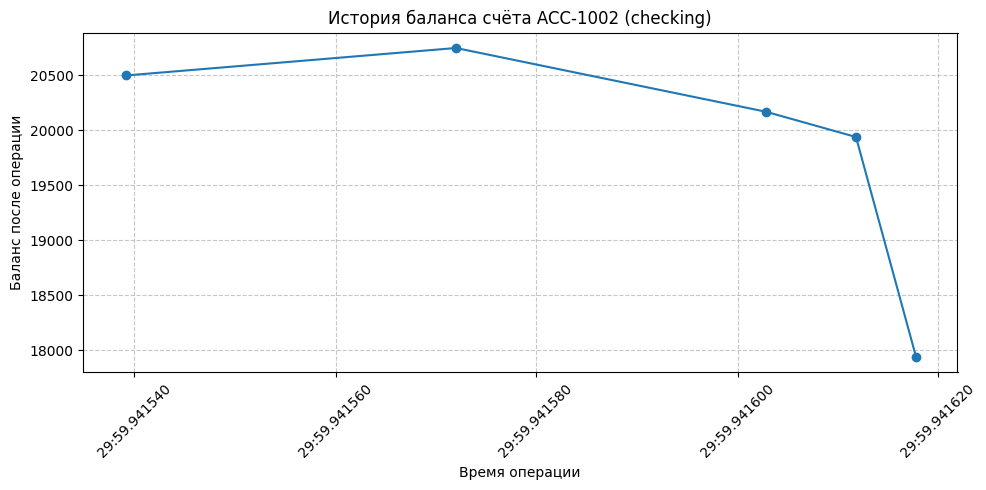

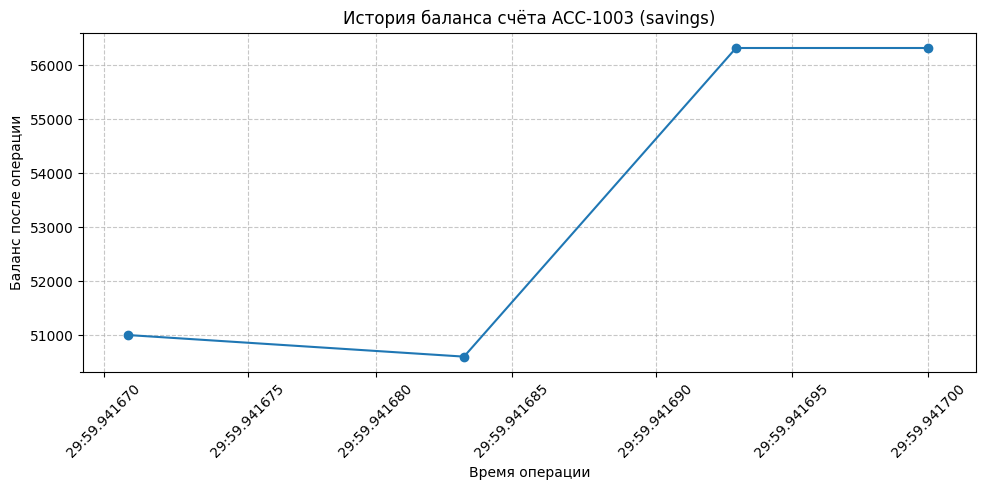

In [26]:
checking.plot_balance_history()
savings.plot_balance_history()

In [27]:
import pandas as pd
from IPython.display import display


def operations_df(operations):
    return pd.DataFrame(
        [
            {
                "Дата и время": op.tstamp,
                "Тип": op.operation_type.value,
                "Сумма": op.amount,
                "Баланс после операции": op.balance_after,
                "Статус": op.status.value,
            }
            for op in operations
        ],
        columns=[
            "Дата и время", "Тип", "Сумма",
            "Баланс после операции", "Статус",
        ],
    )


print(f"Расчётный счёт: {checking.balance}")
display(operations_df(checking.get_history()))

print(f"Сберегательный счёт: {savings.balance}")
display(operations_df(savings.get_history()))


Расчётный счёт: 17939.70


,Дата и время,Тип,Сумма,Баланс после операции,Статус
0,2026-10-24 13:29:59.941539+03:00,deposit,500.00,20500.00,success
1,2026-10-24 13:29:59.941572+03:00,deposit,250.00,20750.00,success
2,2026-10-24 13:29:59.941603+03:00,withdraw,580.30,20169.70,success
3,2026-10-24 13:29:59.941612+03:00,withdraw,230.00,19939.70,success
4,2026-10-24 13:29:59.941618+03:00,withdraw,2000.00,17939.70,success


Сберегательный счёт: 56317.800


,Дата и время,Тип,Сумма,Баланс после операции,Статус
0,2026-10-24 13:29:59.941671+03:00,deposit,500.00,51000.00,success
1,2026-10-24 13:29:59.941683+03:00,withdraw,400.00,50600.00,success
2,2026-10-24 13:29:59.941693+03:00,interest,5717.800,56317.800,success
3,2026-10-24 13:29:59.941700+03:00,withdraw,63000.00,56317.800,fail


#### Выборка последних крупных операций

In [28]:
large_ops = checking.get_large_successful_operations(
    n=5,
    threshold="200",
)
display(operations_df(large_ops))


,Дата и время,Тип,Сумма,Баланс после операции,Статус
0,2026-10-24 13:29:59.941539+03:00,deposit,500.00,20500.00,success
1,2026-10-24 13:29:59.941572+03:00,deposit,250.00,20750.00,success
2,2026-10-24 13:29:59.941603+03:00,withdraw,580.30,20169.70,success
3,2026-10-24 13:29:59.941612+03:00,withdraw,230.00,19939.70,success
4,2026-10-24 13:29:59.941618+03:00,withdraw,2000.00,17939.70,success
